In [6]:
import json
import math
import re
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt

In [7]:
FILE_RE = re.compile(r"^(\d+(?:\.\d+)*)_results\.json$")


def version_key(v: str):
    return tuple(int(p) for p in v.split("."))


def normalize_backend(backend: str) -> str:
    # "PyTorch 2.13.0+cu130 (CPU, 6 threads)" -> "PyTorch (CPU, 6 threads)"
    # so the same series is tracked across torch upgrades.
    return re.sub(r"(PyTorch)\s+\S+", r"\1", backend)


def load(folder: Path):
    """Return {model: {(runner, backend): {version: entry}}} and sorted versions."""
    data = defaultdict(lambda: defaultdict(dict))
    versions = []
    for path in folder.glob("*_results.json"):
        m = FILE_RE.match(path.name)
        if not m:
            continue
        version = m.group(1)
        versions.append(version)
        with open(path) as f:
            doc = json.load(f)
        for model_block in doc["results"]:
            model = model_block["model"]
            for r in model_block["results"]:
                key = (r["runner"], normalize_backend(r["backend"]))
                data[model][key][version] = r
    versions.sort(key=version_key)
    return data, versions

In [8]:
folder = "."
metric = "median_ns"  # choices=["median_ns", "mean_ns", "min_ns", "max_ns"]
linear = True

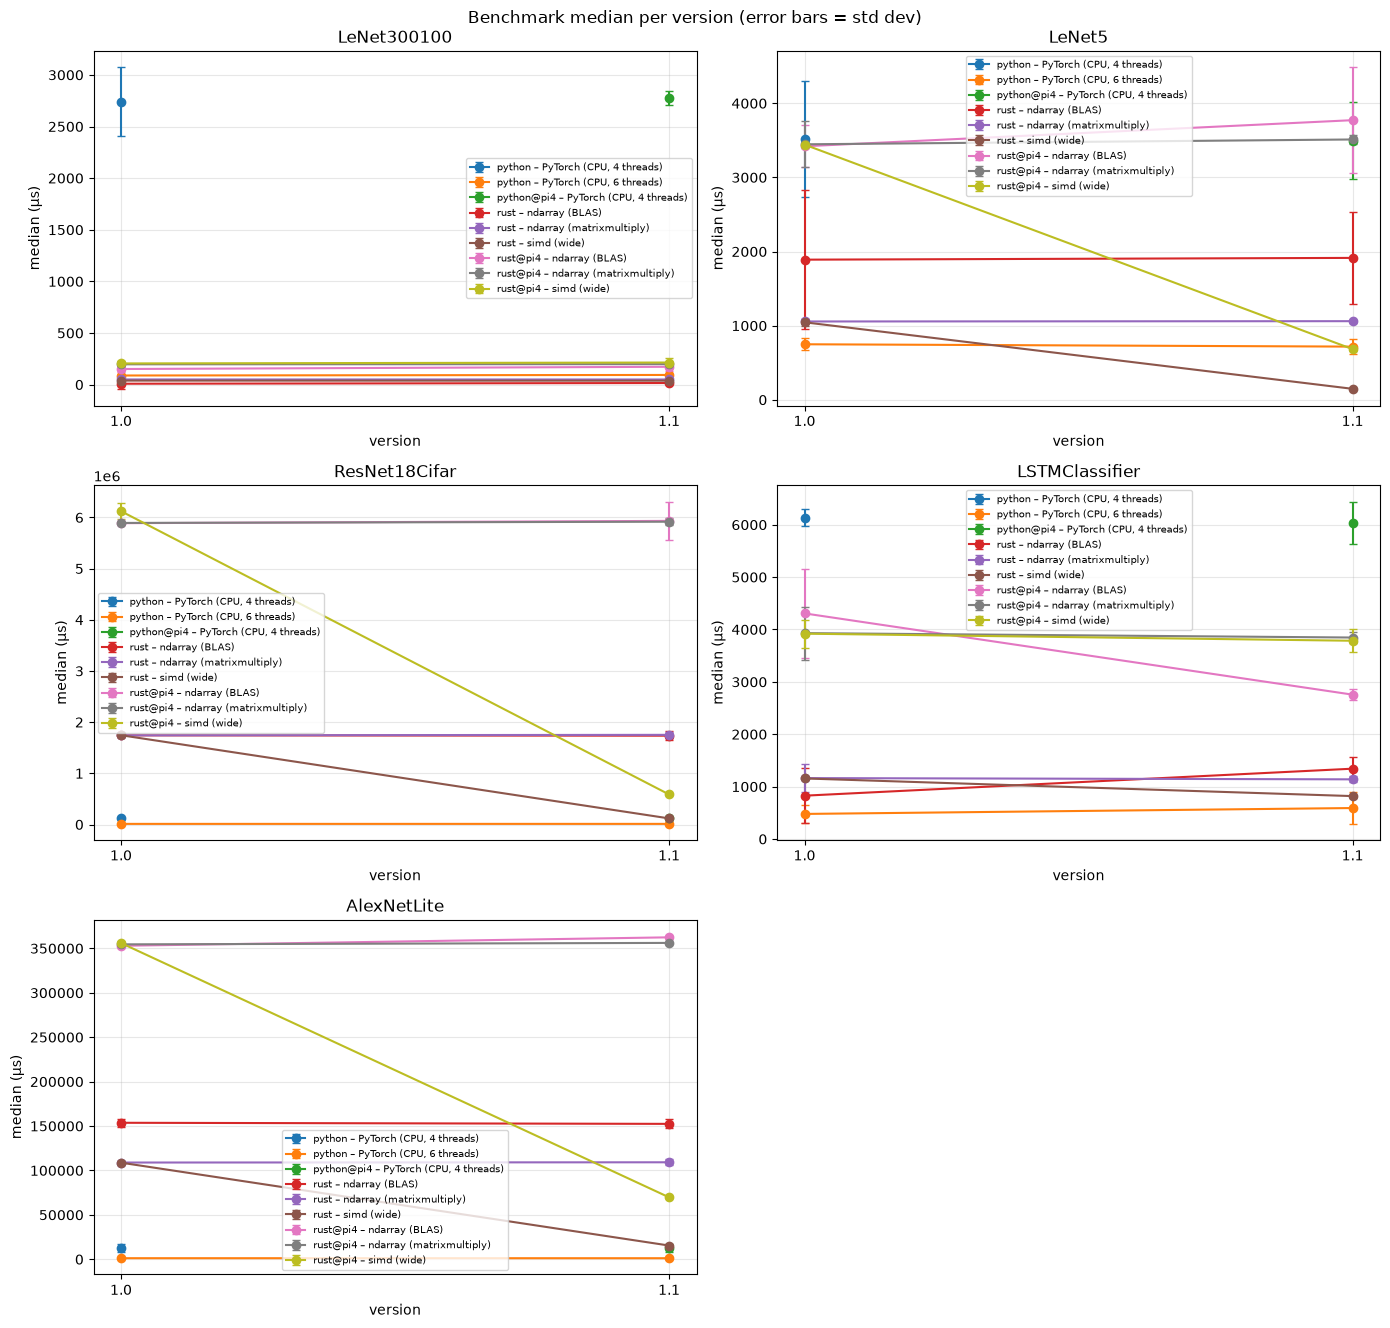

In [11]:
data, versions = load(Path(folder))
if not versions:
    raise SystemExit(f"No '<version>_results.json' files found in {folder}")

models = list(data.keys())
cols = min(2, len(models))
rows = math.ceil(len(models) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(7 * cols, 4.5 * rows), squeeze=False)

x_pos = {v: i for i, v in enumerate(versions)}  # categorical x: evenly spaced

for ax, model in zip(axes.flat, models):
    for (runner, backend), per_version in sorted(data[model].items()):
        vs = [v for v in versions if v in per_version]
        xs = [x_pos[v] for v in vs]
        ys = [per_version[v][metric] / 1e3 for v in vs]  # ns -> µs
        errs = [per_version[v]["std_dev_ns"] / 1e3 for v in vs]
        ax.errorbar(xs, ys, yerr=errs, marker="o", capsize=3, label=f"{runner} – {backend}")
    ax.set_title(model)
    ax.set_xticks(range(len(versions)))
    ax.set_xticklabels(versions)
    ax.set_xlabel("version")
    ax.set_ylabel(f"{metric.replace('_ns', '')} (µs)")
    if not linear:
        ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=7)

for ax in list(axes.flat)[len(models) :]:
    ax.set_visible(False)

fig.suptitle(f"Benchmark {metric.replace('_ns', '')} per version (error bars = std dev)")
fig.tight_layout()
plt.show()